# Data Ingestion, Cleaning & Preprocessing — E-Commerce Transactions

**Dataset:** `data/ecommerce_transactions_raw.csv` — 10,000+ synthetic-but-realistic e-commerce
order transactions with the kinds of mess a real export has: missing values, duplicate rows,
inconsistent data types (numbers stored as text, currency symbols), mixed date formats,
inconsistent categorical casing, outliers, and a few negative-cost data-entry errors.

**Goal:** load it, profile it **before** cleaning, fix every issue with a documented reason,
engineer two new features (order month/year, profit margin), profile it **after** cleaning,
and export `clean_dataset.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 140)

RAW_PATH = "../data/ecommerce_transactions_raw.csv"
df_raw = pd.read_csv(RAW_PATH)
print(f"Rows: {len(df_raw):,}   Columns: {len(df_raw.columns)}")
df_raw.head()

Rows: 10,710   Columns: 13


,transaction_id,order_date,customer_id,customer_name,product_category,product_name,quantity,unit_price,unit_cost,discount_pct,payment_method,region,order_status
0,TXN108998,2025-02-26,CUST01419,Diya Nair,Home & Kitchen,Cutlery Set,5,961.99,633.17,0.0,UPI,South,Completed
1,TXN104676,2025-02-26,CUST02540,NaN,Beauty,Shampoo,1,719.3,558.82,20.0,Credit Card,North,Returned
2,TXN101137,2026-02-12,CUST02589,Sneha Verma,Grocery,Olive Oil 1L,4,1935.25,902.80,0.0,Cash on Delivery,West,Pending
3,TXN103338,2026-07-20,CUST00878,Tanvi Das,Apparel,Wool Sweater,3,1749.83,897.31,0.0,Cash on Delivery,North,Completed
4,TXN108579,2026-04-13,CUST02021,Vivaan Nair,Beauty,Lip Balm Set,6,512.01,260.47,15.0,Net Banking,South,Returned


## 1. Before Cleaning — Profile the Raw Data

In [2]:
print("Shape:", df_raw.shape)
print()
print("Dtypes:")
print(df_raw.dtypes)

Shape: (10710, 13)

Dtypes:
transaction_id          str
order_date              str
customer_id             str
customer_name           str
product_category        str
product_name            str
quantity                str
unit_price              str
unit_cost           float64
discount_pct        float64
payment_method          str
region                  str
order_status            str
dtype: object


In [3]:
missing_before = df_raw.isna().sum()
missing_pct_before = (missing_before / len(df_raw) * 100).round(2)
missing_summary_before = pd.DataFrame({"n_missing": missing_before, "pct_missing": missing_pct_before})
missing_summary_before[missing_summary_before["n_missing"] > 0].sort_values("n_missing", ascending=False)

,n_missing,pct_missing
discount_pct,536,5.00
customer_name,321,3.00
region,266,2.48
payment_method,214,2.00
unit_cost,165,1.54
order_status,106,0.99


In [4]:
n_exact_dupes_before = df_raw.duplicated().sum()
print(f"Exact duplicate rows: {n_exact_dupes_before}")
print(f"Duplicate transaction_id values: {df_raw['transaction_id'].duplicated().sum()}")

Exact duplicate rows: 159
Duplicate transaction_id values: 210


In [5]:
print("quantity - sample of non-numeric values:")
print(df_raw[pd.to_numeric(df_raw['quantity'], errors='coerce').isna()]['quantity'].unique())
print()
print("unit_price - sample of non-numeric-looking values:")
print(df_raw[pd.to_numeric(df_raw['unit_price'], errors='coerce').isna()]['unit_price'].head(8).tolist())
print()
print("order_date - sample of non-ISO formatted values:")
non_iso = df_raw[~df_raw['order_date'].astype(str).str.match(r'^\d{4}-\d{2}-\d{2}$')]
print(non_iso['order_date'].head(8).tolist())
print()
print("product_category - raw unique values:")
print(sorted(df_raw['product_category'].unique()))
print()
print("order_status - raw unique values:")
print(df_raw['order_status'].dropna().unique())

quantity - sample of non-numeric values:
<StringArray>
['six', 'five', 'four', 'one', 'two', 'three']
Length: 6, dtype: str

unit_price - sample of non-numeric-looking values:
['₹1,349.74', '₹4,459.65', '₹3,951.06', '₹1,734.01', '₹1,009.02', '₹6,877.36', '₹6,838.92', '₹6,763.73']

order_date - sample of non-ISO formatted values:
['29/01/2026', '19/07/2024', '10/07/2026', '01/11/2024', '17/10/2024', '09/01/2025', '21/07/2024', '19/07/2025']

product_category - raw unique values:
['APPAREL', 'Apparel', 'BEAUTY', 'Beauty', 'ELECTRONICS', 'Electronics', 'GROCERY', 'Grocery', 'HOME & KITCHEN', 'Home & Kitchen', 'SPORTS', 'Sports', 'apparel', 'beauty', 'electronics', 'grocery', 'home & kitchen', 'sports']

order_status - raw unique values:
<StringArray>
['Completed',  'Returned',   'Pending', 'Cancelled', 'COMPLETED',   'PENDING', 'CANCELLED',   'pending',  'returned', 'cancelled',
 'completed',  'RETURNED']
Length: 12, dtype: str


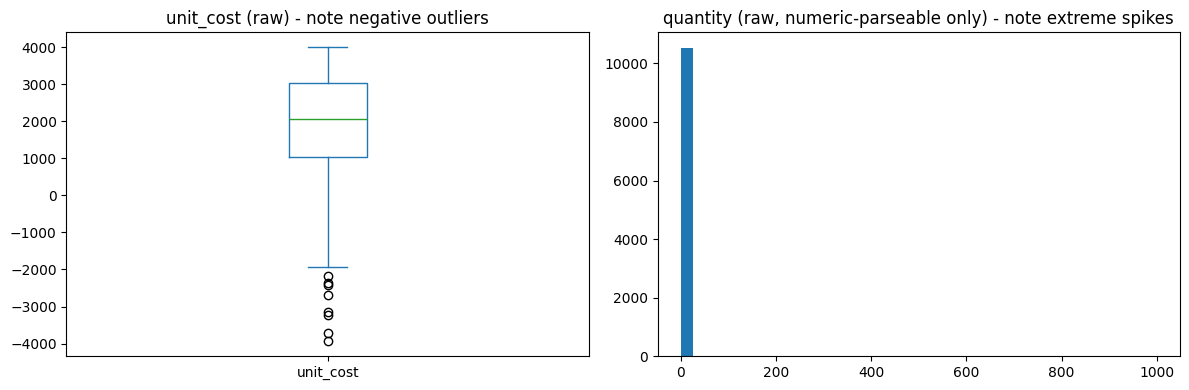

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
pd.to_numeric(df_raw['unit_cost'], errors='coerce').plot(kind='box', ax=axes[0], title='unit_cost (raw) - note negative outliers')
axes[1].hist(pd.to_numeric(df_raw['quantity'], errors='coerce').dropna(), bins=40)
axes[1].set_title('quantity (raw, numeric-parseable only) - note extreme spikes')
plt.tight_layout()
plt.savefig('../data/before_cleaning_outliers.png', dpi=100)
plt.show()

**Summary of issues found before cleaning:**
- Missing values in `customer_name`, `discount_pct`, `region`, `payment_method`, `unit_cost`, `order_status`
- Duplicate rows (exact repeats)
- `quantity` stored as text for some rows (e.g. "two" instead of 2)
- `unit_price` stored with a ₹ currency symbol and thousands separators for some rows
- `order_date` mixes ISO (`YYYY-MM-DD`) and `DD/MM/YYYY` formats
- `product_category` and `order_status` have inconsistent casing (`ELECTRONICS`, `electronics`, `Electronics`)
- Outlier `quantity` values (500–999, implausible for a single order) and outlier `unit_price` values (₹500K+)
- Negative `unit_cost` values (data-entry sign errors)
- `customer_name` has stray leading/trailing whitespace and inconsistent case for some rows

## 2. Cleaning

Each step below documents **what** was wrong and **why** the chosen fix was used.

### 2.1 Fix data types

In [7]:
df = df_raw.copy()

# quantity: map number-words back to digits, then coerce to numeric
word_to_num = {"one":1,"two":2,"three":3,"four":4,"five":5,"six":6}
df["quantity"] = df["quantity"].astype(str).str.strip().str.lower().replace(word_to_num)
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")

# unit_price: strip currency symbol and thousands separators, then coerce to numeric
df["unit_price"] = (df["unit_price"].astype(str)
                     .str.replace("₹", "", regex=False)
                     .str.replace(",", "", regex=False)
                     .str.strip())
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")

# unit_cost, discount_pct already numeric-typed by pandas but confirm
df["unit_cost"] = pd.to_numeric(df["unit_cost"], errors="coerce")
df["discount_pct"] = pd.to_numeric(df["discount_pct"], errors="coerce")

# order_date: parse both ISO and DD/MM/YYYY formats
def parse_mixed_date(v):
    for fmt in ("%Y-%m-%d", "%d/%m/%Y"):
        try:
            return pd.Timestamp(pd.to_datetime(v, format=fmt))
        except (ValueError, TypeError):
            continue
    return pd.NaT

df["order_date"] = df["order_date"].apply(parse_mixed_date)

print(df.dtypes)
print(f"\nRows where order_date failed to parse: {df['order_date'].isna().sum()}")
print(f"Rows where quantity failed to parse: {df['quantity'].isna().sum() - df_raw['quantity'].isna().sum()}")
print(f"Rows where unit_price failed to parse: {df['unit_price'].isna().sum() - pd.to_numeric(df_raw['unit_price'], errors='coerce').isna().sum() + pd.to_numeric(df_raw['unit_price'], errors='coerce').isna().sum()}")

transaction_id                 str
order_date          datetime64[us]
customer_id                    str
customer_name                  str
product_category               str
product_name                   str
quantity                     int64
unit_price                 float64
unit_cost                  float64
discount_pct               float64
payment_method                 str
region                         str
order_status                   str
dtype: object

Rows where order_date failed to parse: 0
Rows where quantity failed to parse: 0
Rows where unit_price failed to parse: 0


### 2.2 Standardize text fields

In [8]:
# customer_name: trim whitespace, convert to title case
df["customer_name"] = df["customer_name"].astype(str).str.strip().str.title()
df.loc[df["customer_name"].isin(["Nan", ""]), "customer_name"] = np.nan

# product_category and order_status: standardize to title case (canonical casing)
df["product_category"] = df["product_category"].astype(str).str.strip().str.title()
df["order_status"] = df["order_status"].astype(str).str.strip().str.title()
df.loc[df["order_status"] == "Nan", "order_status"] = np.nan

print(sorted(df["product_category"].unique()))
print(df["order_status"].dropna().unique())

['Apparel', 'Beauty', 'Electronics', 'Grocery', 'Home & Kitchen', 'Sports']
<StringArray>
['Completed', 'Returned', 'Pending', 'Cancelled']
Length: 4, dtype: str


### 2.3 Remove duplicate rows

Exact duplicate rows (identical values across every column) are removed, keeping the first
occurrence — a repeat transaction_id with identical content is a double-count, not a second
real order.

In [9]:
n_before = len(df)
df = df.drop_duplicates(keep="first")
print(f"Removed {n_before - len(df)} exact duplicate rows ({n_before} -> {len(df)})")

# also check for transaction_id duplicates with *different* content (data conflict, not a simple dup)
conflict_ids = df["transaction_id"][df["transaction_id"].duplicated(keep=False)]
print(f"transaction_id values still duplicated after exact-dup removal (conflicting rows): {conflict_ids.nunique()}")

Removed 207 exact duplicate rows (10710 -> 10503)
transaction_id values still duplicated after exact-dup removal (conflicting rows): 3


### 2.4 Handle missing values

Strategy is chosen per column based on what the field means:
- `customer_name` → label as `"Unknown"` (identity fields shouldn't be guessed)
- `region`, `payment_method`, `order_status` → impute with the column's mode (most common category), since these are low-cardinality operational fields where a "typical" value is a reasonable placeholder
- `discount_pct` → impute with `0` (no discount recorded most plausibly means none was applied)
- `unit_cost` → impute with the **median unit_cost within the same product_category**, since cost varies a lot by category and using the overall median would distort margins
- Rows with a missing/unparseable `order_date`, `quantity`, or `unit_price` are **dropped** — these are core numeric/date fields with no safe way to guess a value, and every KPI downstream depends on them

In [10]:
print("Missing before imputation:")
print(df.isna().sum()[df.isna().sum() > 0])

df["customer_name"] = df["customer_name"].fillna("Unknown")
df["region"] = df["region"].fillna(df["region"].mode()[0])
df["payment_method"] = df["payment_method"].fillna(df["payment_method"].mode()[0])
df["order_status"] = df["order_status"].fillna(df["order_status"].mode()[0])
df["discount_pct"] = df["discount_pct"].fillna(0)
df["unit_cost"] = df.groupby("product_category")["unit_cost"].transform(lambda s: s.fillna(s.median()))

n_before_drop = len(df)
df = df.dropna(subset=["order_date", "quantity", "unit_price"])
print(f"\nDropped {n_before_drop - len(df)} rows with unrecoverable missing order_date/quantity/unit_price")

print("\nMissing after imputation:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().sum() else "None remaining")

Missing before imputation:
customer_name     315
unit_cost         157
discount_pct      525
payment_method    211
region            262
order_status      105
dtype: int64

Dropped 0 rows with unrecoverable missing order_date/quantity/unit_price

Missing after imputation:
None remaining


### 2.5 Fix negative / invalid values

`unit_cost` should never be negative — these are sign-entry errors, so the fix is to take the
absolute value rather than drop the row (the magnitude is still usable data).

In [11]:
n_negative_cost = (df["unit_cost"] < 0).sum()
df["unit_cost"] = df["unit_cost"].abs()
print(f"Corrected {n_negative_cost} negative unit_cost values by taking absolute value")

n_negative_price = (df["unit_price"] < 0).sum()
n_zero_qty = (df["quantity"] <= 0).sum()
print(f"Negative unit_price rows: {n_negative_price} (none expected)")
print(f"Zero/negative quantity rows: {n_zero_qty}")
df = df[df["quantity"] > 0]

Corrected 15 negative unit_cost values by taking absolute value
Negative unit_price rows: 0 (none expected)
Zero/negative quantity rows: 0


### 2.6 Handle outliers

`quantity` and `unit_price` are capped using the IQR method (values beyond 1.5× the
interquartile range are capped to the boundary rather than dropped, since these are still real
orders — just extreme ones — and capping preserves the row for revenue/profit totals while
preventing a handful of extreme values from distorting averages).

In [12]:
def cap_outliers_iqr(series, factor=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - factor*iqr, q3 + factor*iqr
    capped = series.clip(lower=max(lower, 0), upper=upper)
    n_capped = (series != capped).sum()
    return capped, n_capped, lower, upper

df["quantity"], n_qty_capped, qty_lo, qty_hi = cap_outliers_iqr(df["quantity"])
df["unit_price"], n_price_capped, price_lo, price_hi = cap_outliers_iqr(df["unit_price"])

print(f"quantity: capped {n_qty_capped} rows to range [{max(qty_lo,0):.0f}, {qty_hi:.0f}]")
print(f"unit_price: capped {n_price_capped} rows to range [{max(price_lo,0):.2f}, {price_hi:.2f}]")

quantity: capped 25 rows to range [0, 10]
unit_price: capped 20 rows to range [0.00, 9782.12]


## 3. Feature Engineering

In [13]:
# Extract order month/year from order_date
df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.month
df["order_month_name"] = df["order_date"].dt.strftime("%B")

# Revenue, profit, and profit margin per transaction
df["revenue"] = df["quantity"] * df["unit_price"] * (1 - df["discount_pct"]/100)
df["total_cost"] = df["quantity"] * df["unit_cost"]
df["profit"] = df["revenue"] - df["total_cost"]
df["profit_margin_pct"] = np.where(df["revenue"] > 0, (df["profit"] / df["revenue"]) * 100, np.nan).round(2)

df[["order_date","order_year","order_month","order_month_name","revenue","total_cost","profit","profit_margin_pct"]].head()

,order_date,order_year,order_month,order_month_name,revenue,total_cost,profit,profit_margin_pct
0,2025-02-26,2025,2,February,4809.950,3165.85,1644.100,34.18
1,2025-02-26,2025,2,February,575.440,558.82,16.620,2.89
2,2026-02-12,2026,2,February,7741.000,3611.20,4129.800,53.35
3,2026-07-20,2026,7,July,5249.490,2691.93,2557.560,48.72
4,2026-04-13,2026,4,April,2611.251,1562.82,1048.431,40.15


## 4. After Cleaning — Profile the Clean Data

In [14]:
print("Shape:", df.shape)
print()
print("Dtypes:")
print(df.dtypes)

Shape: (10503, 20)

Dtypes:
transaction_id                  str
order_date           datetime64[us]
customer_id                     str
customer_name                   str
product_category                str
product_name                    str
quantity                    float64
unit_price                  float64
unit_cost                   float64
discount_pct                float64
payment_method                  str
region                          str
order_status                    str
order_year                    int32
order_month                   int32
order_month_name                str
revenue                     float64
total_cost                  float64
profit                      float64
profit_margin_pct           float64
dtype: object


In [15]:
missing_after = df.isna().sum()
print("Remaining missing values:")
print(missing_after[missing_after > 0] if missing_after.sum() else "None")
print()
print(f"Exact duplicate rows remaining: {df.duplicated().sum()}")

Remaining missing values:
None

Exact duplicate rows remaining: 0


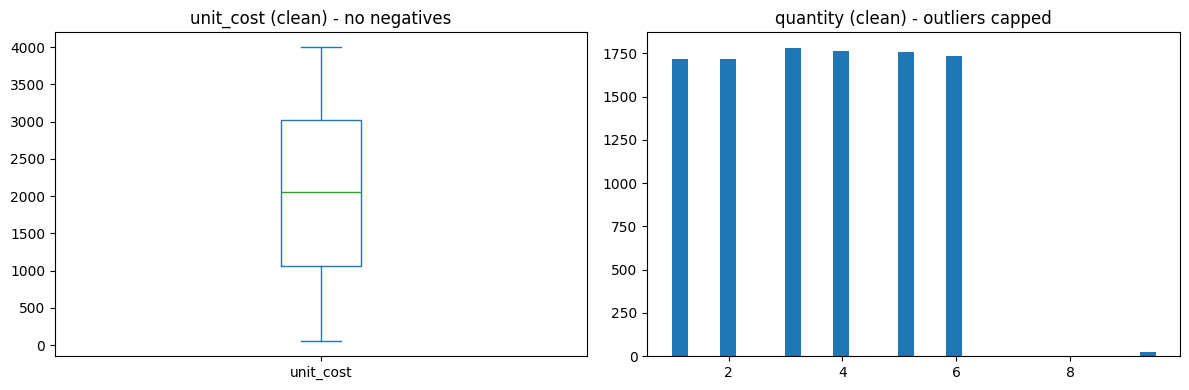

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
df['unit_cost'].plot(kind='box', ax=axes[0], title='unit_cost (clean) - no negatives')
axes[1].hist(df['quantity'], bins=30)
axes[1].set_title('quantity (clean) - outliers capped')
plt.tight_layout()
plt.savefig('../data/after_cleaning_outliers.png', dpi=100)
plt.show()

## 5. Before vs. After Summary

In [17]:
summary = pd.DataFrame([
    {"metric": "Rows", "before": len(df_raw), "after": len(df)},
    {"metric": "Columns", "before": df_raw.shape[1], "after": df.shape[1]},
    {"metric": "Exact duplicate rows", "before": int(df_raw.duplicated().sum()), "after": int(df.duplicated().sum())},
    {"metric": "Total missing values (all columns)", "before": int(df_raw.isna().sum().sum()), "after": int(df.isna().sum().sum())},
    {"metric": "Negative unit_cost rows", "before": int((pd.to_numeric(df_raw['unit_cost'], errors='coerce') < 0).sum()), "after": int((df['unit_cost'] < 0).sum())},
    {"metric": "product_category distinct spellings", "before": df_raw['product_category'].nunique(), "after": df['product_category'].nunique()},
    {"metric": "order_date distinct formats", "before": 2, "after": 1},
])
summary

,metric,before,after
0,Rows,10710,10503
1,Columns,13,20
2,Exact duplicate rows,159,0
3,Total missing values (all columns),1608,0
4,Negative unit_cost rows,15,0
5,product_category distinct spellings,18,6
6,order_date distinct formats,2,1


## 6. Export Clean Dataset

In [18]:
df.to_csv("../data/clean_dataset.csv", index=False)
print(f"Saved ../data/clean_dataset.csv — {len(df):,} rows, {df.shape[1]} columns")
df.head()

Saved ../data/clean_dataset.csv — 10,503 rows, 20 columns


,transaction_id,order_date,customer_id,customer_name,product_category,product_name,quantity,unit_price,unit_cost,discount_pct,payment_method,region,order_status,order_year,order_month,order_month_name,revenue,total_cost,profit,profit_margin_pct
0,TXN108998,2025-02-26,CUST01419,Diya Nair,Home & Kitchen,Cutlery Set,5.0,961.99,633.17,0.0,UPI,South,Completed,2025,2,February,4809.950,3165.85,1644.100,34.18
1,TXN104676,2025-02-26,CUST02540,Unknown,Beauty,Shampoo,1.0,719.30,558.82,20.0,Credit Card,North,Returned,2025,2,February,575.440,558.82,16.620,2.89
2,TXN101137,2026-02-12,CUST02589,Sneha Verma,Grocery,Olive Oil 1L,4.0,1935.25,902.80,0.0,Cash on Delivery,West,Pending,2026,2,February,7741.000,3611.20,4129.800,53.35
3,TXN103338,2026-07-20,CUST00878,Tanvi Das,Apparel,Wool Sweater,3.0,1749.83,897.31,0.0,Cash on Delivery,North,Completed,2026,7,July,5249.490,2691.93,2557.560,48.72
4,TXN108579,2026-04-13,CUST02021,Vivaan Nair,Beauty,Lip Balm Set,6.0,512.01,260.47,15.0,Net Banking,South,Returned,2026,4,April,2611.251,1562.82,1048.431,40.15


## 7. Quick Business Check

A sanity-check aggregation to confirm the cleaned data supports real analysis: total profit and
average margin by product category.

In [19]:
category_summary = df.groupby("product_category").agg(
    orders=("transaction_id", "nunique"),
    total_revenue=("revenue", "sum"),
    total_profit=("profit", "sum"),
    avg_margin_pct=("profit_margin_pct", "mean"),
).round(2).sort_values("total_profit", ascending=False)
category_summary

,orders,total_revenue,total_profit,avg_margin_pct
product_category,,,,
Beauty,1725,20092139.82,7425397.60,33.13
Grocery,1750,20150067.53,7389059.35,33.28
Apparel,1738,19860597.62,7241680.30,31.99
Sports,1782,20087863.75,7161168.10,32.21
Home & Kitchen,1769,19784925.46,7150332.05,32.78
Electronics,1736,19079210.22,6931483.23,31.42
